In [1]:
from config_path import add_to_sys_path
add_to_sys_path()  # Call the function to add path

import numpy as np
from sympy.physics.wigner import wigner_3j,wigner_6j
import sympy as sy
from numpy import linalg as LA
from IPython.display import Latex,display
import matplotlib.pyplot as plt
# import seaborn as sns
# sns.set()
# sns.set_palette('terrain')
from Energy_Levels import MoleculeLevels
from molecule_parameters import get_molecule_params
np.set_printoptions(precision=8, suppress=True)

Added C:\Users\Arian\Code\Molecule-Structure\Source Code to sys.path


In [2]:
%matplotlib qt

In [3]:
# port: H_odd_A now reads A-state H hyperfine h1/2H, dH, which the odd-YbOH A000 dicts lack (KeyError).
# 0 reproduces the Hamiltonian this notebook was run with (the H terms were added in bacb463, 2026-05-07).
A000= MoleculeLevels.initialize_state('YbOH','A','000',[1,2],fermion_or_boson='fermion',isotope='171',params={**get_molecule_params('YbOH','171A','000','fermion'),'h1/2H':0,'dH':0},M_sublevels='all',I_nuclei=[1/2,0],round=8)

No projection values of J provided, using minimal projection 0.5 as default


In [4]:
evals, evecs = A000.eigensystem(0,1e-6,order=True,method='torch')
M0_idx = A000.select_q({'M':[0]})
print(M0_idx)
print('\n')
for i in M0_idx:
    display(Latex('$E = '+str(np.round(A000.evals0[i],4))+r'\:\mathrm{MHz}$'))
    print('Case A:')
    display(Latex(A000.gen_state_str(i,thresh=0.05,round=4)))
    print('\n')
    print('Decoupled:')
    display(Latex(A000.gen_state_str(i,basis='decoupled',thresh=0.05,label_q=['K','M_N','M_S','M_I','M_F'],round=4)))
    print('Case bBS:')
    print('Parity=',A000.parities[i])
    display(Latex(A000.gen_state_str(i,basis='bBS',thresh=0.05,round=4)))

[ 1  3  4  6 10 15 17 20 27 32 37 41]




<IPython.core.display.Latex object>

Case A:


<IPython.core.display.Latex object>



Decoupled:


<IPython.core.display.Latex object>

... (75 outputs left out)



Decoupled:


<IPython.core.display.Latex object>

Case bBS:
Parity= 1.0


<IPython.core.display.Latex object>

In [5]:
# port: H_odd_A now reads A-state H hyperfine h1/2H, dH, which the odd-YbOH A000 dicts lack (KeyError).
# 0 reproduces the Hamiltonian this notebook was run with (the H terms were added in bacb463, 2026-05-07).
A000= MoleculeLevels.initialize_state('YbOH','A','000',[1],fermion_or_boson='fermion',isotope='171',params={**get_molecule_params('YbOH','171A','000','fermion'),'h1/2H':0,'dH':0},M_sublevels='none',I_nuclei=[1/2,1/2],P_values=[1/2],round=8)
# port: X000 was used below but never defined in this notebook. 171, I=[1/2,1/2] matches the saved N=1 index list [3..9];
# N=0-4 matches select_N([4]) below and the commented 171 X000 line in 'Odd Isotope Branching'.
X000= MoleculeLevels.initialize_state('YbOH','X','000',[0,1,2,3,4],fermion_or_boson='fermion',isotope='171',M_sublevels='none',I_nuclei=[1/2,1/2],round=8)

Cannot construct decoupled basis without M values


No projection values of J provided, using minimal projection 0.5 as default
Cannot construct decoupled basis without M values


In [6]:
A000.eigensystem(0.0,0.0);
X000.eigensystem(0.0,0.0);

In [7]:
from Energy_Levels import branching_ratios
from Energy_Levels import XA_branching_ratios

In [8]:
def select_N(N,state):
    idx = []
    N = np.array(N)
    for i,qN in enumerate(state.q_numbers['N']):
        for _N in N:
            if qN == _N:
                idx.append(i)
    return np.array(idx)

def select_J(J,state):
    idx = []
    J = np.array(J)
    for i,qJ in enumerate(state.q_numbers['J']):
        for _J in J:
            if qJ == _J:
                idx.append(i)
    return np.array(idx)

In [9]:
J_idx = A000.select_q({'J':[0.5]})
print(J_idx)
N_idx = X000.select_q({'N':[1]})
print(N_idx)

[0 1 2 3 4 5]
[3 4 5 6 7 8 9]


In [10]:
BR0 = branching_ratios(X000,A000,0,0)

Successfully converted eigenvectors from bBS to aBJ


In [11]:
(y,x) = BR0.shape
h=10
fsize = (h,h*x/y)
fig,axes = plt.subplots(1,1,figsize=(15,10),sharey=True,constrained_layout=True)
axes.matshow(BR0)
axes.grid(False)

In [12]:
def gen_state_str(vector,q_numbers,label_q,thresh=0.02,show_coeff=True):
    full_label = r''
    nonzero_idx = np.nonzero(vector)[0]
    first = 0
    for i,index in enumerate(nonzero_idx):
        coeff = vector[index]
        if abs(coeff) < thresh:
            first+=1
            continue
        sign = {True: '+', False: '-'}[coeff > 0]
        sign0 = {True: ' ', False: sign}[sign=='+']
        if show_coeff:
            label_str = r'${}{}|'.format({True: sign0, False: sign}[i==first],abs(coeff))
        else:
            label_str = r'${}|'.format({True: sign0, False: sign}[i==first])
        val = {q:q_numbers[q][index] for q in label_q}
        for q in label_q:
            _q = {True: '\u039B', False: q}[q=='L']
            _q = {True: '\u03A3', False: _q}[q=='Sigma']
            _q = {True: '\u03A9', False: _q}[q=='Omega']
            if (abs(val[q]) % 1) !=0:
                label_str+=r'{}=\frac{{{}}}{{{}}},'.format(_q,*val[q].as_integer_ratio())
            else:
                label_str+=r'{}={},'.format(_q,int(val[q]))
        label_str = label_str[:-1]+r'\rangle$'
        full_label+=label_str
    if i==first and show_coeff==False:
        full_label = r'$'+full_label[2:]
    return full_label

In [13]:
fig,ax = plt.subplots(figsize=(10,10),constrained_layout=True)
# ax.set_aspect('equal')
A_idx = J_idx[-1]+1
X_idx = N_idx[-1]+1
log=False
BR_plot = BR0
if log:
    BR_plot=np.log10(BR0)
    vmin = -10
    vmax = 0
else:
    vmin=None
    vmax = None
#     log_BR = np.copy(BR0)
#     for i,val1 in enumerate(log_BR):
#         for j,val2 in enumerate(val1):
#             if val2 !=0:
#                 log_BR[i,j] = np.log10(val2)
#     BR_plot = log_BR
mat = ax.matshow(BR_plot[:X_idx,:A_idx],cmap=plt.get_cmap('magma'),vmax = vmax, vmin = vmin)
y = np.arange(0,len(X000.evecs0[:X_idx]))
x = np.arange(0,len(A000.evecs0[:A_idx]))
ax.set_yticks(y)
ax.set_xticks(x)
y_labels = [gen_state_str(X000.evecs0[i],X000.q_numbers,[q for q in X000.q_str if (q=='N' or q=='G' or q=='F1' or q=='F')],thresh=0.2,show_coeff=False) for i in range(y.size)]
x_labels = [gen_state_str(A000.evecs0[i],A000.q_numbers,[q for q in A000.q_str if (q=='L' or q=='J' or q=='F1' or q=='F')],thresh=0.2,show_coeff=False) for i in range(x.size)]
ax.set_yticklabels(y_labels, rotation=40, fontsize=12, ha='right')
ax.set_xticklabels(x_labels, rotation=40, fontsize=12,ha='left')
ax.tick_params(axis='both',labelsize=10,direction='out')
ax.grid(True,which='major',color='white',ls='--',linewidth=0.5)
ax.grid(False,which='minor')
(bot,top) = ax.get_ylim()
ax.set_ylim(bot+0.5, top-0.5)
cbar = fig.colorbar(mat, ax=ax,fraction=0.015, pad=0.05)
#ax.set_xlim(-0.5,x.size+0.5);

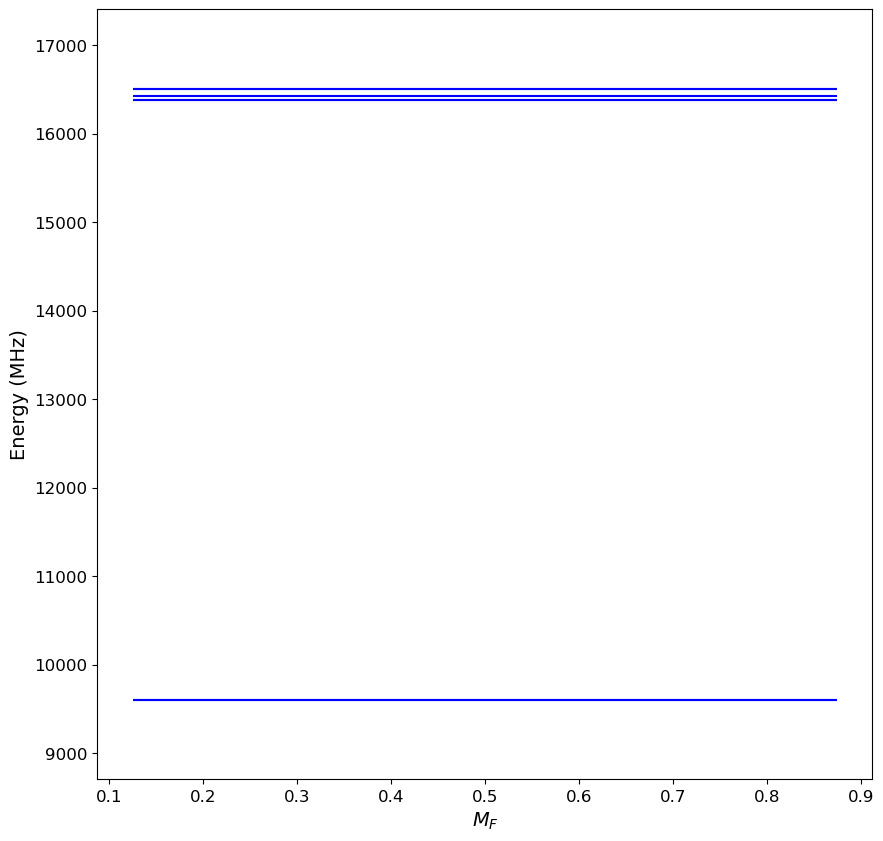

In [14]:
X000.display_levels(0,0,pattern_q='F',idx=N_idx)

In [15]:
N_idx = select_N([4],X000)
s = slice(N_idx[0],N_idx[-1]+1)

In [16]:
s

slice(26, 34, None)

In [17]:
BR0[s].sum(axis=0)

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.00000009, 0.00000009])

In [18]:
def select_N(N,state):
    idx = []
    N = np.array(N)
    for i,qN in enumerate(state.q_numbers['N']):
        for _N in N:
            if qN == _N:
                idx.append(i)
    return np.array(idx)

def select_J(J,state):
    idx = []
    J = np.array(J)
    for i,qJ in enumerate(state.q_numbers['J']):
        for _J in J:
            if qJ == _J:
                idx.append(i)
    return np.array(idx)

In [19]:
J_idx = select_J([0.5],A000)
print(J_idx)
N_idx = select_N([0,2],X000)
print(N_idx)

[0 1 2 3 4 5]
[ 0  1  2 10 11 12 13 14 15 16 17]


In [20]:
for i in J_idx:
    print(i, A000.evals0[i])
    display(Latex(A000.gen_state_str(i,basis=None,label_q=None,thresh=0.000000001,show_coeff=True,new_line=False,round=16)))

0 931.95684629


<IPython.core.display.Latex object>

1 931.95684629


<IPython.core.display.Latex object>

2 1280.01


<IPython.core.display.Latex object>

... (2 outputs left out)

4 14406.94067902


<IPython.core.display.Latex object>

5 14406.94067902


<IPython.core.display.Latex object>

In [21]:
for i in N_idx:
    print(i, X000.evals0[i])
    display(Latex(X000.gen_state_str(i,basis='bBS',label_q=None,thresh=0.000001,show_coeff=True,new_line=False,round=None)))

0 -5117.68563859


<IPython.core.display.Latex object>

1 1703.42769367


<IPython.core.display.Latex object>

2 1707.02596283


<IPython.core.display.Latex object>

... (12 outputs left out)

16 45947.78752015


<IPython.core.display.Latex object>

17 45947.91461159


<IPython.core.display.Latex object>